In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    average_precision_score,)

In [2]:
from pathlib import Path
import joblib

artifact_dir = Path("../models/artifacts")

preprocessor = joblib.load(
    artifact_dir / "preprocessor.joblib"
)

data=joblib.load(artifact_dir/'processed_data.joblib')

x_train_processed=data['X_train']
x_test_processed=data['X_test']
y_train=data['y_train']
y_test=data['y_test']
print("Training data:", x_train_processed.shape)
print("Testing data:", x_test_processed.shape)

Training data: (5634, 46)
Testing data: (1409, 46)


In [4]:
logistic_model = LogisticRegression(max_iter=100,random_state=42,class_weight='balanced')
logistic_model.fit(x_train_processed, y_train)

y_pred=logistic_model.predict(x_test_processed)
y_prob = logistic_model.predict_proba(x_test_processed)[:, 1]

In [5]:
results = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred),
    "Recall": recall_score(y_test, y_pred),
    "F1 Score": f1_score(y_test, y_pred),
    "ROC-AUC": roc_auc_score(y_test, y_prob),
    "PR-AUC": average_precision_score(y_test, y_prob)
}

for metric, score in results.items():
    print(f"{metric}: {score:.4f}")

Accuracy: 0.7381
Precision: 0.5043
Recall: 0.7834
F1 Score: 0.6136
ROC-AUC: 0.8415
PR-AUC: 0.6325


In [6]:
print(classification_report(
    y_test,
    y_pred,
    target_names=["No Churn", "Churn"]
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

              precision    recall  f1-score   support

    No Churn       0.90      0.72      0.80      1035
       Churn       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409

Confusion Matrix:
[[747 288]
 [ 81 293]]


In [7]:
baseline_results = {
    "Model": "Logistic Regression",
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred),
    "Recall": recall_score(y_test, y_pred),
    "F1": f1_score(y_test, y_pred),
    "ROC_AUC": roc_auc_score(y_test, y_prob),
    "PR_AUC": average_precision_score(y_test, y_prob)
}

print(baseline_results)

{'Model': 'Logistic Regression', 'Accuracy': 0.7381121362668559, 'Precision': 0.504302925989673, 'Recall': 0.7834224598930482, 'F1': 0.6136125654450262, 'ROC_AUC': 0.841501976284585, 'PR_AUC': 0.6325016828753636}


In [8]:
from sklearn.ensemble import RandomForestClassifier

forest=RandomForestClassifier(n_estimators=100,max_depth=None,min_samples_split=5,min_samples_leaf=2,class_weight='balanced',random_state=42,n_jobs=-1)
forest.fit(x_train_processed,y_train)

rf_pred=forest.predict(x_test_processed)
rf_prob=forest.predict_proba(x_test_processed)[:,1]

rf_results = {
    "Model": "Random Forest",
    "Accuracy": accuracy_score(y_test, rf_pred),
    "Precision": precision_score(y_test, rf_pred),
    "Recall": recall_score(y_test, rf_pred),
    "F1": f1_score(y_test, rf_pred),
    "ROC_AUC": roc_auc_score(y_test, rf_prob),
    "PR_AUC": average_precision_score(y_test, rf_prob)
}

print(rf_results)

print("\nClassification Report:")
print(classification_report(
    y_test,
    rf_pred,
    target_names=["No Churn", "Churn"]
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, rf_pred))

{'Model': 'Random Forest', 'Accuracy': 0.7686302342086586, 'Precision': 0.548582995951417, 'Recall': 0.7245989304812834, 'F1': 0.6244239631336406, 'ROC_AUC': 0.8363507194709241, 'PR_AUC': 0.6343075674234683}

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.89      0.78      0.83      1035
       Churn       0.55      0.72      0.62       374

    accuracy                           0.77      1409
   macro avg       0.72      0.75      0.73      1409
weighted avg       0.80      0.77      0.78      1409


Confusion Matrix:
[[812 223]
 [103 271]]


In [9]:
import pandas as pd

model_comparison = pd.DataFrame([
    baseline_results,
    rf_results
])

model_comparison.set_index("Model", inplace=True)

model_comparison.round(4)

,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
Model,,,,,,
Logistic Regression,0.7381,0.5043,0.7834,0.6136,0.8415,0.6325
Random Forest,0.7686,0.5486,0.7246,0.6244,0.8364,0.6343


In [10]:
from xgboost import XGBClassifier

xgb_model=XGBClassifier(n_estimators=100,max_depth=4,learning_rate=0.01,subsample=0.8,colsample_bytree=0.8,objective='binary:logistic',eval_metric='logloss',random_state=42,n_jobs=-1)
xgb_model.fit(x_train_processed,y_train)

xgb_pred=xgb_model.predict(x_test_processed)
xgb_prob=xgb_model.predict_proba(x_test_processed)[:,1]

xgb_results={
    "Model": "XGBoost",
    "Accuracy": accuracy_score(y_test, xgb_pred),
    "Precision": precision_score(y_test, xgb_pred),
    "Recall": recall_score(y_test, xgb_pred),
    "F1": f1_score(y_test, xgb_pred),
    "ROC_AUC": roc_auc_score(y_test, xgb_prob),
    "PR_AUC": average_precision_score(y_test, xgb_prob)
}

print(xgb_results)

print("\nClassification Report:")
print(classification_report(
    y_test,
    xgb_pred,
    target_names=["No Churn", "Churn"]
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, xgb_pred))

{'Model': 'XGBoost', 'Accuracy': 0.7799858055358411, 'Precision': 0.7253521126760564, 'Recall': 0.27540106951871657, 'F1': 0.3992248062015504, 'ROC_AUC': 0.8452995427419979, 'PR_AUC': 0.6554873713638755}

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.79      0.96      0.87      1035
       Churn       0.73      0.28      0.40       374

    accuracy                           0.78      1409
   macro avg       0.76      0.62      0.63      1409
weighted avg       0.77      0.78      0.74      1409


Confusion Matrix:
[[996  39]
 [271 103]]


In [11]:
model_comparison = pd.DataFrame([
    baseline_results,
    rf_results,
    xgb_results
])

model_comparison.set_index("Model", inplace=True)

model_comparison.round(4)

,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
Model,,,,,,
Logistic Regression,0.7381,0.5043,0.7834,0.6136,0.8415,0.6325
Random Forest,0.7686,0.5486,0.7246,0.6244,0.8364,0.6343
XGBoost,0.7800,0.7254,0.2754,0.3992,0.8453,0.6555


In [12]:
from sklearn.model_selection import train_test_split

X_fit, X_val, y_fit, y_val = train_test_split(
    x_train_processed,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

xgb_tuning_model = XGBClassifier(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

xgb_tuning_model.fit(X_fit, y_fit)

val_prob = xgb_tuning_model.predict_proba(X_val)[:, 1]

In [13]:
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = [0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50]

threshold_results = []

for threshold in thresholds:
    val_pred = (val_prob >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(y_val, val_pred, zero_division=0),
        "Recall": recall_score(y_val, val_pred),
        "F1": f1_score(y_val, val_pred)
    })

threshold_df = pd.DataFrame(threshold_results)

threshold_df.round(4)

,Threshold,Precision,Recall,F1
0,0.20,0.4855,0.8395,0.6152
1,0.25,0.5232,0.7926,0.6303
2,0.30,0.5561,0.7625,0.6432
3,0.35,0.5928,0.7157,0.6485
4,0.40,0.6125,0.6555,0.6333
5,0.45,0.6418,0.5753,0.6067
6,0.50,0.6901,0.4916,0.5742


In [14]:
best_threshold_row = threshold_df.loc[
    threshold_df["F1"].idxmax()
]

best_threshold = best_threshold_row["Threshold"]

print("Selected threshold:", best_threshold)
print("\nValidation metrics:")
print(best_threshold_row)

Selected threshold: 0.35

Validation metrics:
Threshold    0.350000
Precision    0.592798
Recall       0.715719
F1           0.648485
Name: 3, dtype: float64


In [15]:
model_comparison = pd.DataFrame([
    baseline_results,
    rf_results,
    xgb_results
])

model_comparison = model_comparison.set_index("Model")

model_comparison.round(4)

,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
Model,,,,,,
Logistic Regression,0.7381,0.5043,0.7834,0.6136,0.8415,0.6325
Random Forest,0.7686,0.5486,0.7246,0.6244,0.8364,0.6343
XGBoost,0.7800,0.7254,0.2754,0.3992,0.8453,0.6555


In [16]:
from xgboost import XGBClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import average_precision_score
import optuna

cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=42)

def objective(trial):
    params={
        'n_estimators':trial.suggest_int('n_estimators',200,800),
        'max_depth':trial.suggest_int('max_depth',2,8),
        'learning_rate':trial.suggest_float('learning_rate',0.01,0.2,log=True),
        'subsample':trial.suggest_float('subsample',0.6,1.0),
        'colsample_bytree':trial.suggest_float('colsample_bytree',0.6,1.0),
        'min_child_weight':trial.suggest_int('min_child_weight',1,10),
        'gamma':trial.suggest_float('gamma',0,5)
        ,"reg_alpha": trial.suggest_float(
            "reg_alpha", 1e-5, 10, log=True
        ),
        "reg_lambda": trial.suggest_float(
            "reg_lambda", 1e-5, 10, log=True
        ),
        "objective": "binary:logistic",
        "eval_metric": "logloss",
        "random_state": 42,
        "n_jobs": -1
    }

    model=XGBClassifier(**params)
    scores=cross_val_score(model,x_train_processed,y_train,cv=cv,scoring='average_precision',n_jobs=-1)
    return scores.mean()

c:\Users\mahad\OneDrive\Desktop\Intelligent Customer Risk & Churn Prediction Platform\customer-risk-intelligence\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [17]:
study=optuna.create_study(direction='maximize',study_name='xgboost_churn_prediction',sampler=optuna.samplers.TPESampler(seed=42))
study.optimize(objective,n_trials=50)
print("Best PR-AUC:", study.best_value)

print("\nBest Hyperparameters:")

for param, value in study.best_params.items():
    print(f"{param}: {value}")

[I 2026-11-03 14:18:09,276] A new study created in memory with name: xgboost_churn_prediction
[I 2026-11-03 14:18:24,836] Trial 0 finished with value: 0.6309216100210578 and parameters: {'n_estimators': 425, 'max_depth': 8, 'learning_rate': 0.08960785365368121, 'subsample': 0.8394633936788146, 'colsample_bytree': 0.6624074561769746, 'min_child_weight': 2, 'gamma': 0.2904180608409973, 'reg_alpha': 1.574189004745663, 'reg_lambda': 0.040428727350273294}. Best is trial 0 with value: 0.6309216100210578.
[I 2026-11-03 14:18:31,854] Trial 1 finished with value: 0.6618269442803448 and parameters: {'n_estimators': 625, 'max_depth': 2, 'learning_rate': 0.18276027831785724, 'subsample': 0.9329770563201687, 'colsample_bytree': 0.6849356442713105, 'min_child_weight': 2, 'gamma': 0.9170225492671691, 'reg_alpha': 0.0006690421166498799, 'reg_lambda': 0.014077923139972392}. Best is trial 1 with value: 0.6618269442803448.
[I 2026-11-03 14:18:34,212] Trial 2 finished with value: 0.6628927394042876 and pa

Best PR-AUC: 0.67373487966849

Best Hyperparameters:
n_estimators: 559
max_depth: 5
learning_rate: 0.018525643236852487
subsample: 0.6353041632215166
colsample_bytree: 0.9933786913323791
min_child_weight: 1
gamma: 3.3881249030732072
reg_alpha: 1.5891598037682895
reg_lambda: 3.6467214377222336e-05


In [24]:
import optuna
import plotly
import numpy as np

from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_score

print("Optuna:", optuna.__version__)
print("Plotly:", plotly.__version__)

Optuna: 5.0.0
Plotly: 7.1.0


In [28]:
print("Best CV PR-AUC:", study.best_value)

print("\nBest Hyperparameters:")
for param, value in study.best_params.items():
    print(f"{param}: {value}")

Best CV PR-AUC: 0.67373487966849

Best Hyperparameters:
n_estimators: 559
max_depth: 5
learning_rate: 0.018525643236852487
subsample: 0.6353041632215166
colsample_bytree: 0.9933786913323791
min_child_weight: 1
gamma: 3.3881249030732072
reg_alpha: 1.5891598037682895
reg_lambda: 3.6467214377222336e-05


In [30]:
import pandas as pd

df = pd.read_csv("../data/processed/telco_churn_cleaned.csv")

df["Churn"] = df["Churn"].map({"No": 0, "Yes": 1})

X = df.drop(columns=["customerID", "Churn"])
y = df["Churn"]

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(X_train.shape)
print(X_test.shape)
print(X_train.dtypes)

(5634, 24)
(1409, 24)
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges        float64
ExpectedCharges     float64
ChargeRatio         float64
Churn_numeric         int64
HasPhoneService       int64
HasMultipleLines      int64
dtype: object


In [32]:
best_params = study.best_params.copy()

best_params.update({ "objective": "binary:logistic",
    "eval_metric": "logloss",
    "random_state": 42,
    "n_jobs": -1})

xgb_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", XGBClassifier(**best_params))
])

from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier

xgb_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", XGBClassifier(**best_params))
])

xgb_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](24,)","['gender','SeniorCitizen','Partner',...,'Churn_numeric','HasPhoneService', 'HasMultipleLines']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,24
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``rem

In [33]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

y_prob = xgb_pipeline.predict_proba(X_test)[:, 1]
y_pred = (y_prob >= 0.5).astype(int)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1:", f1_score(y_test, y_pred))
print("ROC-AUC:", roc_auc_score(y_test, y_prob))
print("PR-AUC:", average_precision_score(y_test, y_prob))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.8026969481902059
Precision: 0.6578947368421053
Recall: 0.5347593582887701
F1: 0.5899705014749262
ROC-AUC: 0.8491151928492081
PR-AUC: 0.6610817351823908

Confusion Matrix:
[[931 104]
 [174 200]]

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.90      0.87      1035
           1       0.66      0.53      0.59       374

    accuracy                           0.80      1409
   macro avg       0.75      0.72      0.73      1409
weighted avg       0.79      0.80      0.80      1409



In [34]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

oof_prob=cross_val_predict(xgb_pipeline,X_train,y_train,cv=cv,method='predict_proba',n_jobs=-1)[:,1]
threshold_results = []

for threshold in np.arange(0.20, 0.71, 0.05):
    pred = (oof_prob >= threshold).astype(int)
    threshold_results.append({
        "threshold": round(threshold, 2),
        "precision": precision_score(y_train, pred),
        "recall": recall_score(y_train, pred),
        "f1": f1_score(y_train, pred)
    })

threshold_df = pd.DataFrame(threshold_results)
threshold_df.round(3)


,threshold,precision,recall,f1
0,0.20,0.485,0.860,0.620
1,0.25,0.517,0.811,0.632
2,0.30,0.548,0.756,0.636
3,0.35,0.580,0.700,0.634
4,0.40,0.621,0.650,0.636
5,0.45,0.650,0.595,0.621
6,0.50,0.668,0.540,0.598
7,0.55,0.690,0.472,0.560
8,0.60,0.712,0.396,0.509
9,0.65,0.749,0.331,0.459


In [35]:
CHURN_THRESHOLD = 0.30

y_pred = (y_prob >= CHURN_THRESHOLD).astype(int)


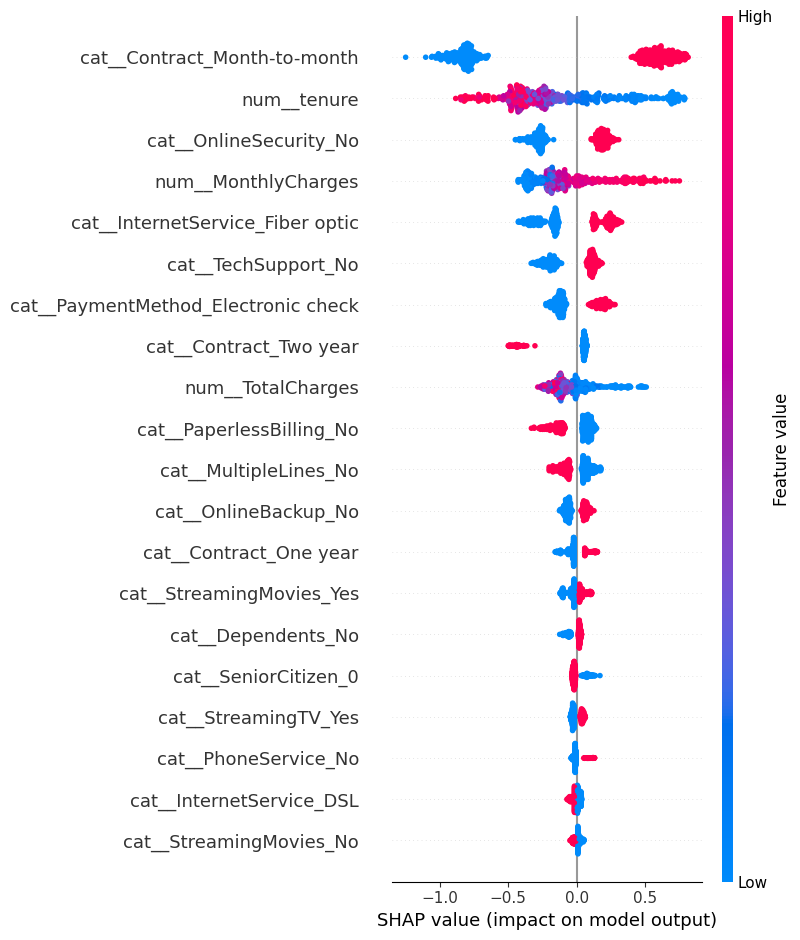

In [36]:
import shap
import matplotlib.pyplot as plt

preprocessor_fitted = xgb_pipeline.named_steps["preprocessor"]
xgb_model = xgb_pipeline.named_steps["classifier"]

X_sample = X_train.sample(
    n=min(500, len(X_train)),
    random_state=42
)
X_sample_transformed = preprocessor_fitted.transform(X_sample)

if hasattr(X_sample_transformed, "toarray"):
    X_sample_transformed = X_sample_transformed.toarray()

feature_names = preprocessor_fitted.get_feature_names_out()

explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer.shap_values(X_sample_transformed)

shap.summary_plot(
    shap_values,
    X_sample_transformed,
    feature_names=feature_names
)

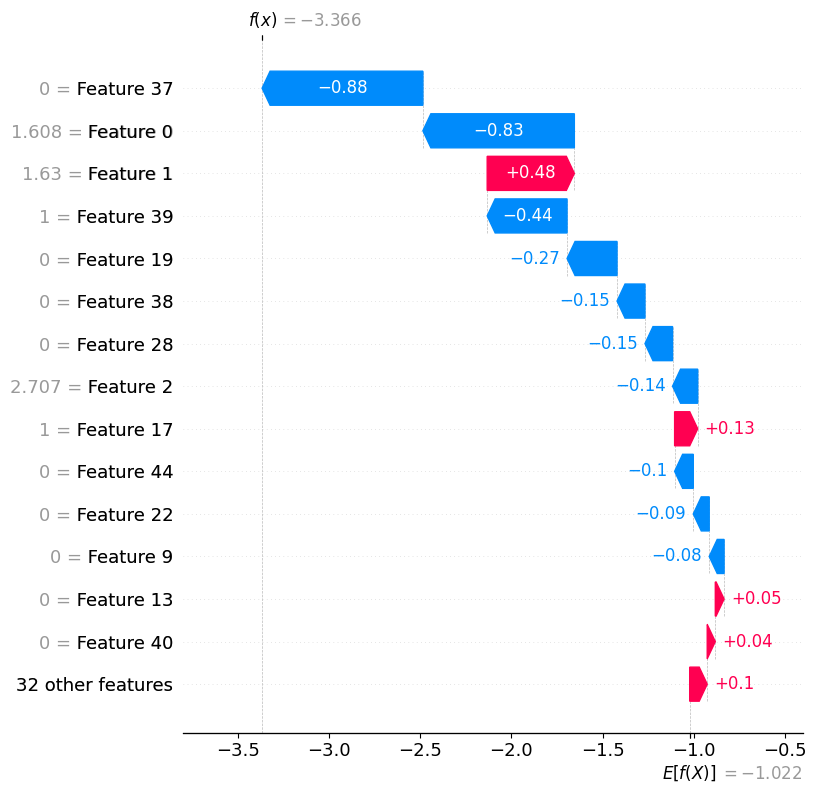

In [37]:
import shap
import numpy as np
import matplotlib.pyplot as plt

# Select one customer from the test dataset
customer = X_test.iloc[[0]]

# Transform using the fitted preprocessing pipeline
customer_transformed = (
    xgb_pipeline.named_steps["preprocessor"]
    .transform(customer)
)

if hasattr(customer_transformed, "toarray"):
    customer_transformed = customer_transformed.toarray()

# Generate SHAP explanation
explainer = shap.TreeExplainer(
    xgb_pipeline.named_steps["classifier"]
)

shap_explanation = explainer(customer_transformed)

# Display individual customer explanation
shap.plots.waterfall(
    shap_explanation[0],
    max_display=15
)

In [38]:
customer_probability = xgb_pipeline.predict_proba(customer)[0, 1]

print("Churn Probability:", round(customer_probability, 4))
print(
    "Risk Category:",
    "High" if customer_probability >= 0.70
    else "Medium" if customer_probability >= 0.30
    else "Low"
)

Churn Probability: 0.0334
Risk Category: Low


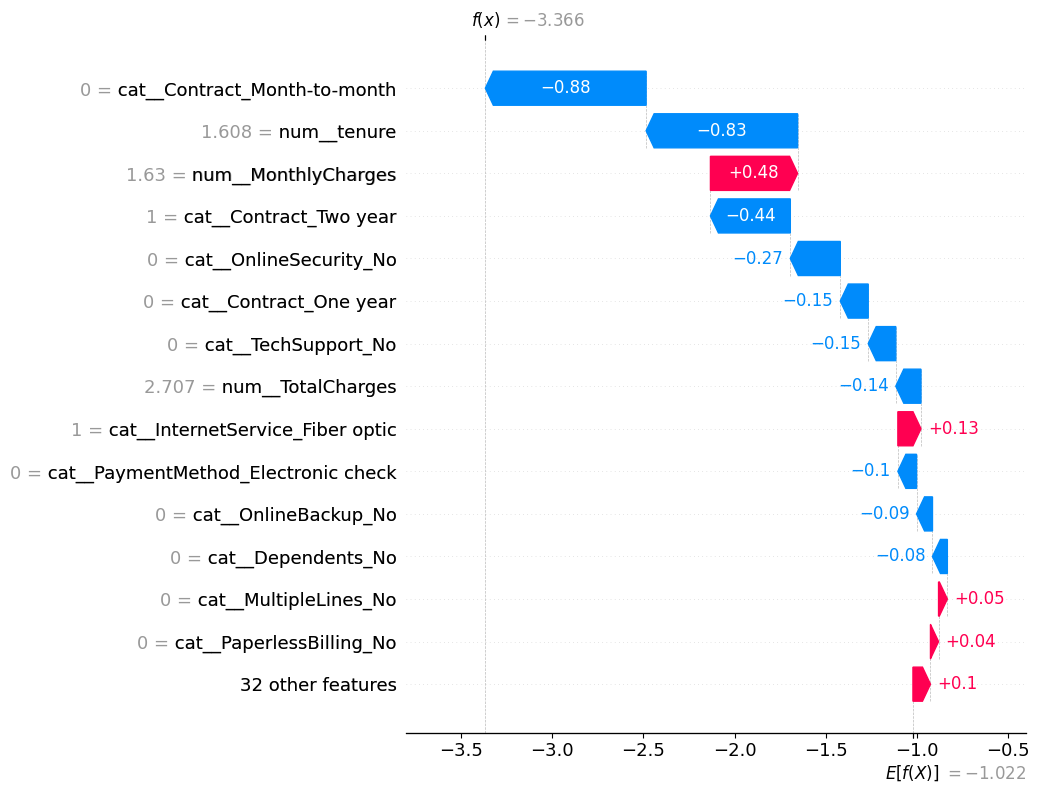

In [39]:
feature_names = (
    xgb_pipeline
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

X_customer_transformed = (
    xgb_pipeline
    .named_steps["preprocessor"]
    .transform(customer)
)

if hasattr(X_customer_transformed, "toarray"):
    X_customer_transformed = X_customer_transformed.toarray()

explainer = shap.TreeExplainer(
    xgb_pipeline.named_steps["classifier"]
)

shap_values = explainer(X_customer_transformed)

shap.plots.waterfall(
    shap.Explanation(
        values=shap_values.values[0],
        base_values=shap_values.base_values[0],
        data=X_customer_transformed[0],
        feature_names=feature_names
    ),
    max_display=15
)

In [40]:
from pathlib import Path
import joblib
import json
from datetime import datetime,timezone

artifact_dir=Path('../model/artifacts')
artifact_dir.mkdir(parents=True,exist_ok=True)

joblib.dump(xgb_pipeline,artifact_dir/'churn_pipeline.joblib')

model_config={ 
    "model_name": "Tuned XGBoost",
    "threshold": 0.30,
    "risk_bands": {
        "low": [0.0, 0.30],
        "medium": [0.30, 0.70],
        "high": [0.70, 1.0]
    },
    "target": "Churn",
    "positive_class": 1}

with open(artifact_dir / "model_config.json", "w") as f:
    json.dump(model_config, f, indent=4)

metadata = {
    "project": "Customer Risk Intelligence Platform",
    "algorithm": "XGBoost",
    "training_rows": len(X_train),
    "features": len(X_train.columns),
    "created_at": datetime.now(timezone.utc).isoformat(),
    "evaluation": {
        "accuracy": 0.8027,
        "precision": 0.6579,
        "recall": 0.5348,
        "f1": 0.5900,
        "roc_auc": 0.8491,
        "pr_auc": 0.6611
    }
}

with open(artifact_dir / "model_metadata.json", "w") as f:
    json.dump(metadata, f, indent=4)

In [41]:
loaded_model = joblib.load(
    artifact_dir / "churn_pipeline.joblib"
)

test_probability = loaded_model.predict_proba(X_test.iloc[:5])[:, 1]

print(test_probability)

[0.03337319 0.7942593  0.05826576 0.32261732 0.02211267]
